# 01 · Measured information freshness in a real U-space system (BUBBLES)

This notebook does something the research plan assumed would have to be
*emulated*: it **measures** Age of Information directly, in an operational
U-space validation environment, on **two independent campaign days**.

**Age of Information** is read directly from the UTM track records as
`t − t_last`, where the dataset documentation defines `t_last` as *"Timestamp
from the last message received from the drone"*. Crucially this is a
**single-clock** difference, computed inside the UTM's own time base, so it is
immune to synchronisation error between aircraft and ground.

> **Retraction.** An earlier version of this notebook also reported a measured
> one-way latency as `time_ms − message.time`. The dataset documentation
> describes `time_ms` as *"Arrival time to the MQTT server (**ignore**)"*, and
> the data bears that out: day 2 yields **negative** one-way delays for every
> aircraft. That result has been withdrawn and is not used anywhere in this
> study. The evidence for the withdrawal is retained below, because the failure
> mode is itself worth reporting.

> **Claim discipline.** BUBBLES is a real campaign, but with 13–14 aircraft over
> several km² it is *not* a high-density scenario. It bounds the low end of the
> density axis; it does not stand in for dense operations.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)

import numpy as np
import pandas as pd
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

from telemetry_freshness.viz import style as S, figures as F
S.use_paper_style()
print("working dir:", ROOT)

working dir: /path/to/Field_Measurement_of_Age_of_Information


In [2]:
from telemetry_freshness.data.bubbles import BubblesDataset
from telemetry_freshness.evaluation.density import airborne_only, density_timeline

ds = BubblesDataset()
DAYS = ds.scenarios()
truth, obs = {}, {}
for d in DAYS:
    truth[d] = ds.load_scenario(d)
    o = ds.load_observations(d)
    obs[d] = o[~o.is_probe]

display(pd.DataFrame([{
    "day": d,
    "telemetry_messages": len(truth[d]),
    "aircraft": truth[d].uas_id.nunique(),
    "duration_h": round((truth[d].t_s.max()-truth[d].t_s.min())/3600, 2),
    "utm_track_rows": len(obs[d]),
    "utm_conflict_alerts": int(obs[d].tactical_conflict.sum()),
} for d in DAYS]))

,day,telemetry_messages,aircraft,duration_h,utm_track_rows,utm_conflict_alerts
0,2022_04_11,69643,14,2.77,67986,28819
1,2022_04_12,38472,13,3.09,39505,15163


### Data-integrity note

Day 1's telemetry logs contain **injected system-test probe messages** mixed in
with real flight data: a placeholder payload (attitude 4/4/4, ground speed
exactly 20, `pilot_alerts` as the string `"none"`), an uptime rather than epoch
clock, and a position ~40 km NW of the site. The adapter excludes them by
default. Day 2 contains none.

In [3]:
probe = BubblesDataset(include_probe_messages=True)
for d in DAYS:
    g = probe.load_scenario(d)
    n = int(g.is_probe.sum())
    print(f"{d}: {n:,} probe messages excluded from ground truth, "
          f"{int(ds.load_observations(d).is_probe.sum()):,} probe tracks flagged")

2022_04_11: 6,544 probe messages excluded from ground truth, 802 probe tracks flagged
2022_04_12: 0 probe messages excluded from ground truth, 0 probe tracks flagged


## Measured Age of Information — the headline quantity

In [4]:
rows = []
for d in DAYS:
    a = obs[d].aoi_s.dropna()
    rows.append({"day": d, "n": len(a), "mean": a.mean(), "p50": a.median(),
                 "p75": a.quantile(.75), "p90": a.quantile(.90), "p95": a.quantile(.95),
                 "p99": a.quantile(.99), "max": a.max()})
AOI = pd.DataFrame(rows).round(3)
display(AOI)
AOI.to_csv("results/processed/C1_aoi_by_day.csv", index=False)

,day,n,mean,p50,p75,p90,p95,p99,max
0,2022_04_11,67986,1.614,0.597,0.907,1.882,3.745,18.324,410.110
1,2022_04_12,39505,3.746,0.567,0.850,1.122,4.446,98.808,407.113


**The centre replicates; the tail does not.** Median AoI is 0.597 s and 0.567 s
on the two days — a 5% difference. The P99 is 18.3 s and 98.8 s — a factor of
five. Both days are heavy-tailed, but *how* heavy is not a stable property of
the system.

This is the first of three places in this study where a distribution's centre is
well-behaved and its tail is not, and it is why every requirement in this work
is stated against a tail statistic.

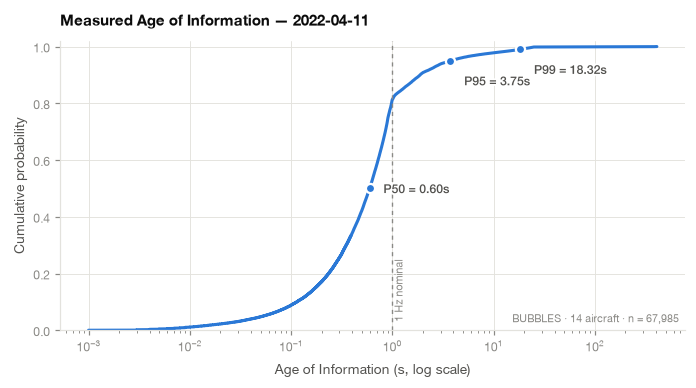

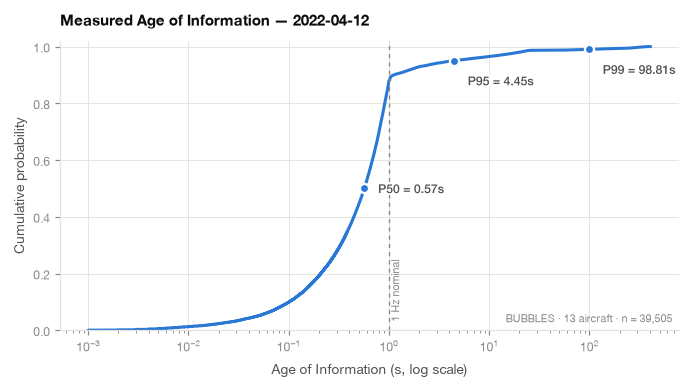

In [5]:
for d in DAYS:
    fig, ax = F.fig_aoi_distribution(
        obs[d].aoi_s,
        title=f"Measured Age of Information — {d.replace('_','-')}",
        label=f"BUBBLES · {truth[d].uas_id.nunique()} aircraft",
        reference={"1 Hz nominal": 1.0})
    S.save(fig, f"F0_bubbles_aoi_cdf_{d}"); S.plt.show()

In [6]:
per_ac = []
for d in DAYS:
    t = (obs[d].groupby("uas_id").aoi_s
         .agg(n="size", p50="median", p95=lambda s: s.quantile(.95),
              p99=lambda s: s.quantile(.99)).round(3))
    t["day"] = d
    per_ac.append(t)
display(pd.concat(per_ac).sort_values(["day","p95"], ascending=[True,False]))

,n,p50,p95,p99,day
uas_id,,,,,
PLV-Mzoom-1,3117,1.194,9.585,21.282,2022_04_11
PLV-Mdual-2,5055,0.595,8.654,358.870,2022_04_11
UAW-Valaq,3201,0.684,6.022,18.078,2022_04_11
ASD-Madv-4,4801,0.600,5.301,19.645,2022_04_11
BV-Madv-1,4862,0.585,3.438,16.802,2022_04_11
UPV-Mavic-2,5169,0.581,3.339,19.212,2022_04_11
ADS-Phanthom,5801,0.608,3.332,16.933,2022_04_11
PLV-Mzoom-2,3330,0.623,3.261,16.596,2022_04_11
PLB-Madv-3,3425,0.528,3.151,18.211,2022_04_11


## Why the cross-clock latency measurement was withdrawn

Retained as evidence for the retraction above, and because it is a caution for
anyone attempting to measure information age in the field.

In [7]:
rows = []
for d in DAYS:
    l = truth[d].latency_s.dropna()
    # Jitter = deviation from each aircraft's own median, so a constant
    # per-aircraft clock offset cancels and only the variable part survives.
    j = (truth[d].dropna(subset=["latency_s"])
         .groupby("uas_id").latency_s.transform(lambda s: s - s.median()).abs())
    rows.append({"day": d, "n": len(l),
                 "latency_p50": l.median(), "latency_p95": l.quantile(.95),
                 "latency_max": l.max(),
                 "jitter_p50": j.median(), "jitter_p95": j.quantile(.95)})
LAT = pd.DataFrame(rows).round(3)
display(LAT)
LAT.to_csv("results/processed/C1_latency_by_day.csv", index=False)

,day,n,latency_p50,latency_p95,latency_max,jitter_p50,jitter_p95
0,2022_04_11,69643,0.519,1.243,9.217,0.051,0.292
1,2022_04_12,38472,-1.624,-0.813,8.863,0.046,0.430


In [8]:
for d in DAYS:
    t = (truth[d].dropna(subset=["latency_s"]).groupby("uas_id").latency_s
         .agg(n="size", p50="median", iqr=lambda s: s.quantile(.75)-s.quantile(.25)).round(3))
    print(f"=== {d} — per-aircraft median latency (s) ===")
    print(f"  all medians {'POSITIVE' if (t.p50>0).all() else 'NEGATIVE'}; "
          f"range {t.p50.min():+.3f} to {t.p50.max():+.3f}; median IQR {t.iqr.median():.3f}")
    display(t)

=== 2022_04_11 — per-aircraft median latency (s) ===
  all medians NEGATIVE; range -0.231 to +1.442; median IQR 0.137


,n,p50,iqr
uas_id,,,
ADS-Phanthom,6292,-0.231,0.142
ASD-Madv-4,4742,0.451,0.042
BV-Madv-1,4908,0.548,0.092
BV-Madv-2,5890,0.557,0.073
PLB-Madv-3,3633,0.528,0.136
PLB-Mzoom-3,5744,0.559,0.179
PLV-Mdual-1,5236,0.506,0.052
PLV-Mdual-2,5105,0.785,0.381
PLV-Mzoom-1,1972,1.176,0.172


=== 2022_04_12 — per-aircraft median latency (s) ===
  all medians NEGATIVE; range -2.878 to -0.817; median IQR 0.060


,n,p50,iqr
uas_id,,,
ADS-Phanthom,4107,-2.878,0.292
BV-Madv-1,4843,-1.456,0.228
BV-Madv-2,1812,-1.609,0.027
PLB-Madv-3,1942,-1.647,0.060
PLB-Mzoom-3,1636,-1.628,0.032
PLV-Mdual-1,3181,-1.416,0.483
PLV-Mdual-2,4110,-1.620,0.249
PLV-Mzoom-1,2284,-0.836,0.050
PLV-Mzoom-2,2079,-2.059,0.052


**Day 2's latencies are all negative** — every aircraft, clustered tightly
(median per-aircraft IQR 0.05 s) around roughly −1.6 s, with one at −2.88 s. A
negative one-way delay is not physical. The tight per-aircraft spread shows this
is a **constant clock offset per airframe**, not variable transport delay, and
the documentation's instruction to ignore `time_ms` explains why.

Note what is *not* affected. The variable component — jitter, measured as
deviation from each aircraft's own median, so a constant offset cancels —
replicates across both days (P95 0.292 s versus 0.430 s). And **AoI is
untouched on either day**, because it never crosses a clock boundary.

**Methodological finding.** Measuring information age by cross-clock
differencing is fragile in a real multi-operator deployment: one of two days was
unusable for it, and nothing in the data itself would have flagged that had the
documentation not been consulted. The single-clock `t − t_last` construction is
the robust instrument, and field measurement of AoI should prefer it.

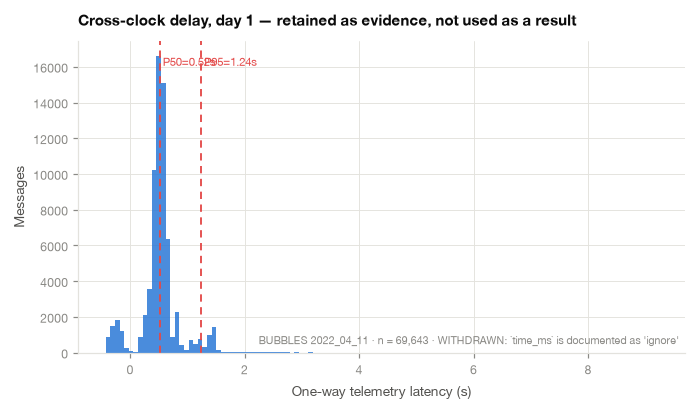

In [9]:
d = DAYS[0]
lat = truth[d].latency_s.dropna()
lat = lat[lat.between(-1, 30)]
fig, ax = S.plt.subplots(figsize=(6.4, 3.8))
ax.hist(lat, bins=120, color=S.CATEGORICAL[0], alpha=0.85, edgecolor="none")
for q, lbl in ((.5, "P50"), (.95, "P95")):
    v = lat.quantile(q)
    ax.axvline(v, color=S.STATUS["critical"], lw=1.2, ls=(0, (4, 3)))
    ax.text(v, ax.get_ylim()[1]*0.92, f" {lbl}={v:.2f}s", fontsize=7.5,
            color=S.STATUS["critical"])
ax.set_xlabel("One-way telemetry latency (s)"); ax.set_ylabel("Messages")
ax.set_title("Cross-clock delay, day 1 — retained as evidence, not used as a result")
S.annotate_note(ax, f"BUBBLES {d} · n = {len(lat):,} · WITHDRAWN: `time_ms` is documented as 'ignore'")
S.finish(fig, ax); S.save(fig, "S3_withdrawn_crossclock_delay"); S.plt.show()

## Traffic density actually achieved

In [10]:
rows = []
for d in DAYS:
    air = airborne_only(truth[d])
    dt = density_timeline(air, step_s=60)
    dt = dt[dt.n_aircraft >= 2]
    rows.append({"day": d, "windows": len(dt),
                 "aircraft_max": int(dt.n_aircraft.max()),
                 "density_min": dt.density_per_km2.min(),
                 "density_median": dt.density_per_km2.median(),
                 "density_max": dt.density_per_km2.max()})
display(pd.DataFrame(rows).round(2))
print("Real density is ~0.4-3 UAS/km2 on both days: a real campaign, but not a")
print("dense one. High-density conditions must be extrapolated, and labelled so.")

,day,windows,aircraft_max,density_min,density_median,density_max
0,2022_04_11,81,14,0.42,1.14,3.14
1,2022_04_12,46,11,0.50,1.32,14828.17


Real density is ~0.4-3 UAS/km2 on both days: a real campaign, but not a
dense one. High-density conditions must be extrapolated, and labelled so.


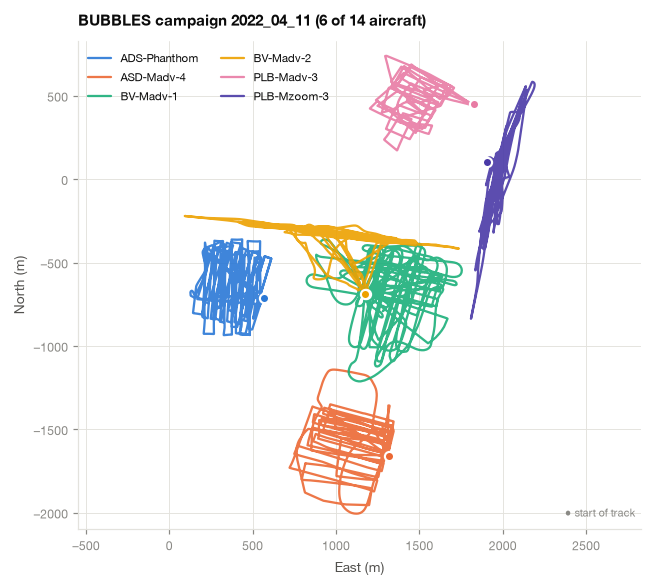

In [11]:
fig, ax = F.fig_trajectory_map(airborne_only(truth[DAYS[0]]),
                               title=f"BUBBLES campaign {DAYS[0]} (6 of 14 aircraft)")
S.save(fig, "S2_bubbles_tracks"); S.plt.show()

## Link-delay pool for the validity check

Exported for the link-model validity check (notebook 12). **Day 1 only.**

Because it derives from the withdrawn `time_ms` field, this pool is used
**only** to test whether the *shape* of a delay distribution changes conclusions
relative to a constant of the same mean — a question about modelling choices,
not a claim about this deployment's true latency. No result in the paper depends
on its absolute level.

In [12]:
from pathlib import Path
src = truth[DAYS[0]].latency_s.dropna()
pool = src[src.between(0, 10)].to_numpy()
Path("data/processed").mkdir(parents=True, exist_ok=True)
np.save("data/processed/bubbles_latency_pool_s.npy", pool)
prov = ds.provenance(DAYS[0])
prov.notes.append("latency pool: day 1 only; day 2 excluded for per-aircraft clock offsets")
prov.to_json("data/processed/bubbles_latency_pool.provenance.json")
print(f"saved {pool.size:,} measured latency samples from {DAYS[0]}")
print(f"  mean {pool.mean():.3f}  p50 {np.median(pool):.3f}  "
      f"p95 {np.percentile(pool,95):.3f}  p99 {np.percentile(pool,99):.3f}  max {pool.max():.2f}")

saved 63,948 measured latency samples from 2022_04_11
  mean 0.595  p50 0.532  p95 1.316  p99 1.511  max 9.22
